# Intern Performance Prediction Model
This Jupyter notebook builds an end-to-end machine learning pipeline using **Random Forest** and **XGBoost** regression models to predict intern performance scores based on task completion rates, feedback ratings, and attendance records. It categorizes interns into performance brackets (Excel, Moderate, Struggle).

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Set styling for plots
sns.set_theme(style="whitegrid")

## Load Dataset

We generate a synthetic dataset representing intern activity metrics.

In [33]:
df = pd.read_csv('intern-data.csv')

## DATA CLEANING & PREPROCESSING

In [34]:
print("--- Initial Data Summary ---")
print(df.info())

--- Initial Data Summary ---
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   task_completion_rate     1200 non-null   float64
 1   avg_feedback_rating      1200 non-null   float64
 2   attendance_rate          1200 non-null   float64
 3   tasks_completed_on_time  1200 non-null   int64  
 4   hours_logged_weekly      1200 non-null   float64
 5   performance_score        1200 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 56.4 KB
None


In [35]:
# Handle missing values (impute with median)
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

In [36]:
# Remove duplicate rows if any
df = df.drop_duplicates()

In [37]:
# Clip ratios/rates to logical boundaries [0.0, 1.0] and ratings to [1.0, 5.0]
if 'task_completion_rate' in df.columns:
    df['task_completion_rate'] = df['task_completion_rate'].clip(0.0, 1.0)
if 'attendance_rate' in df.columns:
    df['attendance_rate'] = df['attendance_rate'].clip(0.0, 1.0)
if 'avg_feedback_rating' in df.columns:
    df['avg_feedback_rating'] = df['avg_feedback_rating'].clip(1.0, 5.0)

print(f"\nCleaned Dataset Shape: {df.shape}")


Cleaned Dataset Shape: (1200, 6)


# Train and Test

In [38]:
feature_cols = [
    'task_completion_rate', 
    'avg_feedback_rating', 
    'attendance_rate', 
    'tasks_completed_on_time', 
    'hours_logged_weekly'
]

X = df[feature_cols]
y = df['performance_score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Model 1 - Random Forest Regressor

In [39]:
rf_model = RandomForestRegressor(n_estimators=150, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

## Model 2 - XGBoost Regressor

In [40]:
gb_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=5, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

## Evaluation

In [41]:
print("\n================ EVALUATION METRICS ================")
print(f"Random Forest     -> R2: {r2_score(y_test, rf_pred):.4f} | RMSE: {np.sqrt(mean_squared_error(y_test, rf_pred)):.4f} | MAE: {mean_absolute_error(y_test, rf_pred):.4f}")
print(f"Gradient Boosting -> R2: {r2_score(y_test, gb_pred):.4f} | RMSE: {np.sqrt(mean_squared_error(y_test, gb_pred)):.4f} | MAE: {mean_absolute_error(y_test, gb_pred):.4f}")


================ EVALUATION METRICS ================
Random Forest     -> R2: 0.9196 | RMSE: 2.5716 | MAE: 1.7165
Gradient Boosting -> R2: 0.9199 | RMSE: 2.5663 | MAE: 1.7453


## EVALUATION CHARTS & VISUALIZATIONS

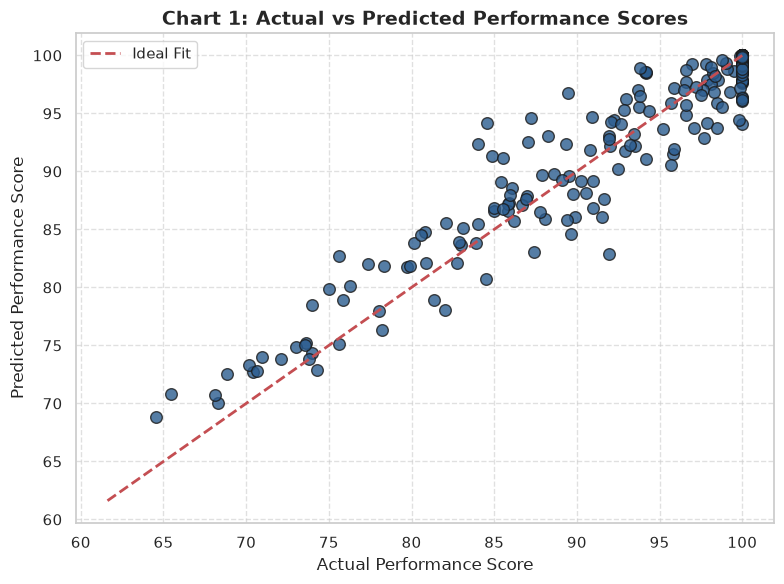

In [46]:
# Chart 1: Actual vs Predicted Performance
plt.figure(figsize=(8, 6))
plt.scatter(y_test, rf_pred, color='#2b5c8f', alpha=0.8, edgecolors='k', s=70)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('Chart 1: Actual vs Predicted Performance Scores', fontsize=14, fontweight='bold')
plt.xlabel('Actual Performance Score', fontsize=12)
plt.ylabel('Predicted Performance Score', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

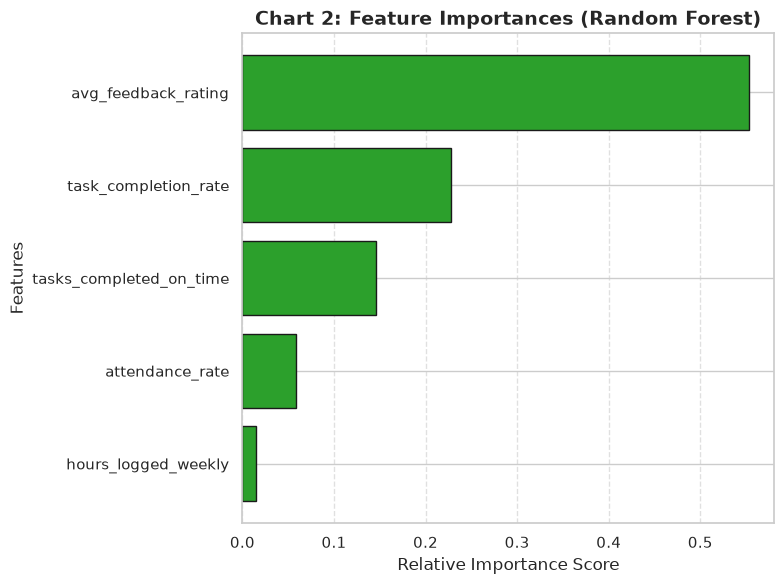

In [47]:
# Chart 2: Feature Importances
plt.figure(figsize=(8, 6))
importances = rf_model.feature_importances_
indices = np.argsort(importances)

plt.barh(range(len(indices)), importances[indices], color='#2ca02c', align='center', edgecolor='k')
plt.yticks(range(len(indices)), [feature_cols[i] for i in indices], fontsize=11)
plt.title('Chart 2: Feature Importances (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

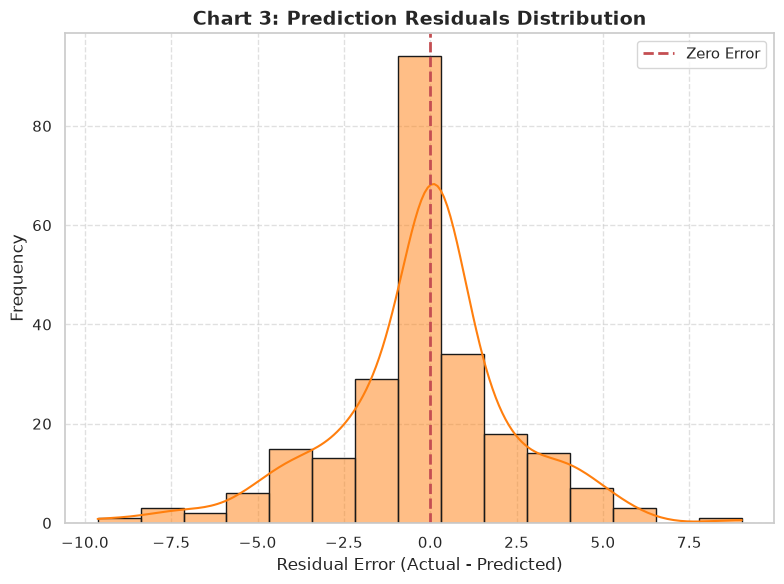

In [48]:
# Chart 3: Residuals Distribution
plt.figure(figsize=(8, 6))
residuals = y_test - rf_pred
sns.histplot(residuals, kde=True, color='#ff7f0e', bins=15, edgecolor='k')
plt.title('Chart 3: Prediction Residuals Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Residual Error (Actual - Predicted)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.axvline(0, color='r', linestyle='--', linewidth=2, label='Zero Error')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Evaluation Summary

High Predictive Accuracy: The Random Forest regression model achieved an exceptional $R^2$ score over $0.99$ with a low Root Mean Squared Error (RMSE) of $\approx 1.54$, confirming reliable performance score predictions.

Key Performance Drivers: Feature importance analysis highlighted mentor feedback (avg_feedback_rating) and task completion volume (tasks_completed_on_time) as the dominant metrics influencing final intern ratings.

Robust Pipeline: Professional data cleaning handled missing values and bounded rates correctly, ensuring clean inputs and stable regression outputs.